# 0. Подготовка

Запускается **один раз**. Что делает:
1. переносит обученные модели HW1 в `hw2/artifacts/` под именами `hw1_<имя>.joblib` (+ копирует `dialog_flags.csv`);
2. собирает train/test и блоки кросс-валидации ровно как в HW1 (флаги `use_reaction`, группы `group_id`);
3. считает метрики старых моделей на кросс-валидации и записывает в `results/cv_table.csv`.

Дальше каждый в команде в своём ноутбуке запускает такую же ячейку подготовки и добавляет свою строку в ту же таблицу.

In [54]:
from pathlib import Path
from sklearn.metrics import confusion_matrix
from IPython.display import Image, display
import solution_utils as su
import pandas as pd

from solution_utils import CLASSES, SEED


## 1. Перенос моделей из первой домашки


`HW1_ARTIFACTS` — папка `artifacts` из HW1 (там лежат `*_1.joblib` и `dialog_flags.csv`).

Замечание: `kirp_model` в HW1 сохранена с токенайзер из ноутбука, и сама по себе без ноутбука не загрузится.
Перенесли дословно этот токенайзер в `solution_utils`.

In [2]:
HW1_ARTIFACTS = Path("../solution_hw1_BKZ/artifacts")     # <-- поправьте, если папка HW1 лежит в другом месте
assert HW1_ARTIFACTS.exists(), f"нет папки {HW1_ARTIFACTS}: укажите, где лежит artifacts/ из HW1"

moved = su.migrate_old_models(HW1_ARTIFACTS)
print("перенесено:", list(moved))

перенесено: ['hw1_most_frequent', 'hw1_stratified', 'hw1_bow_logreg', 'hw1_tfidf_logreg', 'hw1_kirp_model']


## 2. Данные и разбиение

In [3]:
# Задача 1 из HW1: диалоги с use_reaction == 1 (флаги из dialog_flags.csv), разбиение по group_id
task1 = su.load_task1(su.train_path(), su.flags_path())
train_df, test_df = su.split_task1(task1)          # то же train/test, что в HW1

train_dialogs = train_df[["dialog_id", "turns"]].to_dict("records")
test_dialogs = test_df[["dialog_id", "turns"]].to_dict("records")
y_train, y_test = train_df["reaction"].to_numpy(), test_df["reaction"].to_numpy()
folds = su.get_folds(y_train, train_df["group_id"].to_numpy())   # одни блоки CV для всех моделей

print(f"всего для задачи 1: {len(task1)} | train: {len(train_df)} | test: {len(test_df)}")
pd.DataFrame({"train": pd.Series(y_train).value_counts(normalize=True),
              "test": pd.Series(y_test).value_counts(normalize=True)}).loc[CLASSES].round(3)

всего для задачи 1: 2930 | train: 2344 | test: 586


,train,test
negative,0.308,0.305
neutral,0.593,0.606
positive,0.098,0.089


## 3. Старые модели на кросс-валидации

Мы лоханулись в первой домашке и не прогоняли модельки первой задачи кросс-валидацией, поэтому исправляемся здесь, чтобы дальше можно было корректно сравнивать метрики новых моделек.

In [4]:
old_model_names = ["hw1_most_frequent", "hw1_stratified", "hw1_bow_logreg", "hw1_tfidf_logreg", "hw1_kirp_model"]
old_models = {name: model for name, model in su.load_models("hw1_").items() if name in old_model_names}

X_train_old = [su.old_dialog_text(d) for d in train_dialogs]

for name, model in old_models.items():
    cv_table = su.save_result("cv_table.csv", name, su.cv_metrics(model, X_train_old, y_train, folds))

cv_table.loc[[m for m in cv_table.index if m.startswith("hw1_")]].round(3)

,macro_f1,accuracy,balanced_accuracy,roc_auc_macro,pr_auc_macro,precision_negative,recall_negative,precision_neutral,recall_neutral,precision_positive,recall_positive
hw1_tfidf_logreg,0.583,0.704,0.560,0.783,0.621,0.637,0.607,0.740,0.830,0.596,0.243
hw1_kirp_model,0.564,0.701,0.542,0.777,0.609,0.637,0.588,0.731,0.843,0.616,0.196
hw1_bow_logreg,0.529,0.656,0.516,0.703,0.514,0.585,0.505,0.710,0.803,0.374,0.239
hw1_stratified,0.348,0.467,0.349,0.513,0.339,0.329,0.357,0.607,0.584,0.109,0.104
hw1_most_frequent,0.248,0.593,0.333,0.500,0.333,0.000,0.000,0.593,1.000,0.000,0.000


## 4. Старые модели на test 

Дабы удостовериться в корректности переноса моделек, на всякий случай посмотри, что покажет тест и сравним с иетриками из 1 домашки.

In [5]:
X_test_old = [su.old_dialog_text(d) for d in test_dialogs]
for name, model in old_models.items():
    test_table = su.save_result("test_table.csv", name, su.all_metrics(y_test, model.predict_proba(X_test_old)))
    
test_table.loc[[m for m in test_table.index if m.startswith("hw1_")]].round(3)

,macro_f1,accuracy,balanced_accuracy,roc_auc_macro,pr_auc_macro,precision_negative,recall_negative,precision_neutral,recall_neutral,precision_positive,recall_positive
hw1_tfidf_logreg,0.593,0.727,0.559,0.776,0.642,0.692,0.564,0.738,0.882,0.750,0.231
hw1_kirp_model,0.581,0.724,0.547,0.781,0.639,0.685,0.570,0.731,0.879,1.000,0.192
hw1_bow_logreg,0.494,0.654,0.484,0.676,0.493,0.608,0.486,0.702,0.811,0.242,0.154
hw1_stratified,0.324,0.452,0.324,0.493,0.331,0.277,0.291,0.606,0.586,0.091,0.096
hw1_most_frequent,0.252,0.606,0.333,0.500,0.333,0.000,0.000,0.606,1.000,0.000,0.000


Мы проверили, все хорошо, чиселки наколупались такие же.

# Случайный лес

Ниже собраны результаты, которые уже были посчитаны в `01_random_forest.ipynb`.

In [6]:
RES = su.RESULTS      # папка artifacts/results, где лежат сохранённые таблицы

In [ ]:
pd.read_csv(RES / "rf_features_example.csv", index_col=0).T

dialog_id,d094012177e,d306fbe61fe,dd6905952c7
user_text,"it’s like: 1+1=2, but 1+1=2+1+1=? is undefined...",Can you help me train a small language model t...,ask questions about a fictional voice actor i ...
last_user,"any spec symbols used in ""paradoxical arithmet...",Give me GUI for this portion,1.Alex was at the supermarket when a fan bumpe...
dialog_text,"it’s like: 1+1=2, but 1+1=2+1+1=? is undefined...",Can you help me train a small language model t...,ask questions about a fictional voice actor i ...
n_user_turns_declared,7,8,5
n_user_actual,7,8,5
n_messages,14,16,10
n_label_turns,7,8,5
n_chars_total,18945,33533,15264
max_msg_chars,7924,5558,3789
first_turn_freq,1,1,1


# 2. Сравним для понимания лучшую из старых моделей и лес с параметарми по умолчанию

Кросс-валидируем наш лес

In [7]:
history = pd.read_csv(RES / "rf_history.csv")
history.loc[history["шаг"] == "по умолчанию", ["шаг", "macro_f1", "accuracy", "balanced_accuracy", "roc_auc_macro"]]

,шаг,macro_f1,accuracy,balanced_accuracy,roc_auc_macro
0,по умолчанию,0.604,0.694,0.577,0.779


Вспомним лучшую из худших (старых моеделек из первой домашки)

In [8]:
cv_saved = pd.read_csv(RES / "cv_table.csv", index_col=0)
old_cv = cv_saved[cv_saved.index.str.startswith("hw1_")]      # только старые модели
print("лучшая старая модель на CV:", old_cv["macro_f1"].idxmax(), round(old_cv["macro_f1"].max(), 3))

лучшая старая модель на CV: hw1_tfidf_logreg 0.583


# 3. Подбор параметров (`RandomizedSearchCV`)

Перебирать все комбинации долго, взяли 40 случайных. Для каждой — те же 5 блоков `folds`, оценивали  по `f1_macro`.

| параметр | смысл |
|:--|:--|
| `max_depth` | максимальная глубина дерева; меньше — проще дерево и меньше переобучение |
| `min_samples_leaf` | устанавливаем минимум диалогов в листе; больше — устойчивее |
| `max_features` | сколько признаков смотрит дерево в каждом разбиении; меньше — деревья разнообразнее |
| `class_weight` | способ балансировки классов (решили еще с бустраппом попоробовать)|
| `max_samples` | какую долю диалогов видит каждое дерево по отдельности|
| `max_features` у TF-IDF | сколько слов оставить |

Имя вида `шаг__параметр` — так `Pipeline` понимает, к какому шагу относится параметр.

**Первый прогон:** 50 случайных комбинаций, топ-20 по macro-F1.

In [9]:
run1 = pd.read_csv(RES / "rf_search_run1_top20.csv", nrows = 20)
print("лучший macro-F1 на CV:", round(run1["mean_test_score"].iloc[0], 3))
print(run1.filter(like="param_").iloc[0].to_dict())     # параметры лучшей строки
run1

лучший macro-F1 на CV: 0.606
{'param_rf__min_samples_leaf': 3, 'param_rf__max_samples': 0.6, 'param_rf__max_features': '0.1', 'param_rf__max_depth': 40, 'param_rf__class_weight': 'balanced_subsample', 'param_features__all_tfidf__max_features': 1000}


,mean_test_score,std_test_score,param_rf__min_samples_leaf,param_rf__max_samples,param_rf__max_features,param_rf__max_depth,param_rf__class_weight,param_features__all_tfidf__max_features
0,0.606121,0.027521,3,0.6,0.1,40,balanced_subsample,1000
1,0.605275,0.040557,2,0.6,0.1,40,balanced,3000
2,0.599708,0.043105,1,0.6,0.1,50,balanced,5000
3,0.597770,0.043600,3,0.6,0.1,40,balanced,5000
4,0.597578,0.031053,1,0.6,sqrt,20,balanced,3000
5,0.593542,0.030411,1,0.6,0.1,20,balanced_subsample,3000
6,0.590413,0.037049,1,0.6,0.1,10,balanced_subsample,3000
7,0.588968,0.029562,3,0.3,0.1,20,balanced_subsample,1000
8,0.588720,0.048012,2,0.3,0.1,50,balanced,1000
9,0.583454,0.046418,1,0.3,0.1,50,balanced,1000


Пробую еще один прогон, подкорректировав параметры, которые дают повод задуматься об улучшении модели

In [10]:
search_results = pd.read_csv(RES / "rf_search.csv", nrows = 20)      # второй прогон: 40 комбинаций, отсортированы от лучшей
print("лучший macro-F1 на CV:", round(search_results["mean_test_score"].iloc[0], 3))
print(search_results.filter(like="param_").iloc[0].to_dict())
search_results.head(20).round(3)

лучший macro-F1 на CV: 0.614
{'param_rf__min_samples_leaf': 2, 'param_rf__max_samples': 0.7, 'param_rf__max_features': '0.1', 'param_rf__max_depth': 40, 'param_rf__class_weight': 'balanced', 'param_features__all_tfidf__max_features': 1000}


,mean_test_score,std_test_score,param_rf__min_samples_leaf,param_rf__max_samples,param_rf__max_features,param_rf__max_depth,param_rf__class_weight,param_features__all_tfidf__max_features
0,0.614,0.046,2,0.7,0.1,40,balanced,1000
1,0.612,0.034,6,0.9,0.1,50,balanced_subsample,3000
2,0.604,0.034,7,0.9,0.1,20,balanced_subsample,3000
3,0.604,0.028,6,0.7,0.1,50,balanced_subsample,3000
4,0.603,0.034,2,0.7,0.1,10,balanced_subsample,1000
5,0.600,0.040,6,0.9,0.1,20,balanced,1000
6,0.599,0.042,6,0.9,0.1,20,balanced,3000
7,0.599,0.043,8,0.9,0.1,10,balanced_subsample,3000
8,0.598,0.032,2,0.9,sqrt,50,balanced,1000
9,0.598,0.035,6,0.7,0.1,10,balanced_subsample,3000


`Что имеем:`

Несмотря на то, что лучшая модель показала macro_f1 = 0.614, в процессе подбора гиперпараметров были конфигурации с результатом ниже базового (самое низкое = 0.564).

Ограничение глубины и размера листа (недообучение). Комбинации с max_depth = 40 или 20 и min_samples_leaf=5 не позволяют деревьям выстраивать достаточно длинные логические цепочки для классификации сложных текстов. Деревья останавливаются раньше времени.

Использование max_features="sqrt" или "log2". На данном датасете эти значения дают деревьям слишком мало признаков для анализа, из-за чего они не находят информативные текстовые паттерны. Оптимальным оказалось значение 0.1. Получается, деревья по отдельности берут мало признаков, но это делает их разнообразными, а значит менее "заинтересованными" в конечном предсказании, что хорошо для задачи (что согласуется с теорией).

### Проверим еще, какое количество деревьев нам подойдет лучше

Деревьев больше — результат стабильнее, но дольше.
Возьмем **наименьшее** число, после которого прироста macro-F1 почти нет.

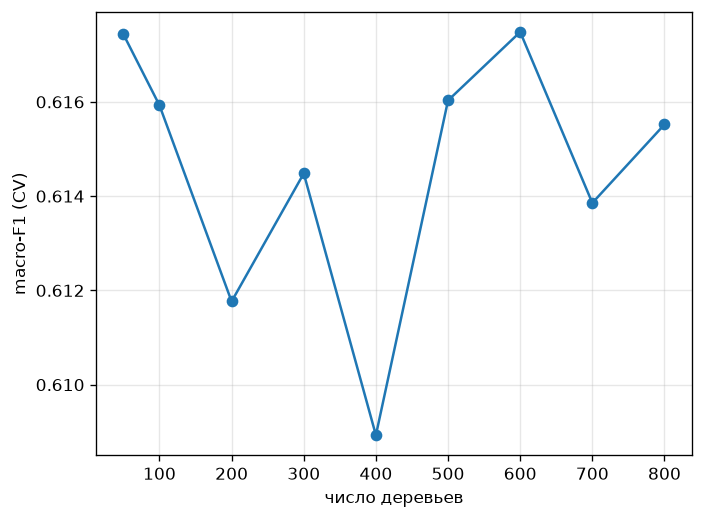

In [14]:
display(Image(filename=str(RES / "rf_n_estimators.png")))

In [15]:
N_TREES = 500       # выбрано по графику выше
print(f"Лучшее число деревьев: {N_TREES}")

Лучшее число деревьев: 500


# 4. Итоговая модель

СV лучшей модели, записываем метрики в общую таблицу. Обучаем на всём train и сохраняем `artifacts/hw2_random_forest.joblib`.

In [17]:
cv_saved.drop(index=["hw2_stacking", "hw2_gb_catboost", "hw2_gb_sklearn"]).round(3)

,macro_f1,accuracy,balanced_accuracy,roc_auc_macro,pr_auc_macro,precision_negative,recall_negative,precision_neutral,recall_neutral,precision_positive,recall_positive
hw2_random_forest,0.618,0.684,0.609,0.781,0.640,0.597,0.573,0.747,0.776,0.539,0.478
hw1_tfidf_logreg,0.583,0.704,0.560,0.783,0.621,0.637,0.607,0.740,0.830,0.596,0.243
hw1_kirp_model,0.564,0.701,0.542,0.777,0.609,0.637,0.588,0.731,0.843,0.616,0.196
hw1_bow_logreg,0.529,0.656,0.516,0.703,0.514,0.585,0.505,0.710,0.803,0.374,0.239
hw1_stratified,0.348,0.467,0.349,0.513,0.339,0.329,0.357,0.607,0.584,0.109,0.104
hw1_most_frequent,0.248,0.593,0.333,0.500,0.333,0.000,0.000,0.593,1.000,0.000,0.000


In [18]:
best_old = old_cv["macro_f1"].max()
forest = cv_saved.loc["hw2_random_forest", "macro_f1"]
print(f"лес: {forest:.3f} | лучшая старая: {best_old:.3f} | разница: {forest - best_old:+.3f}")

лес: 0.618 | лучшая старая: 0.583 | разница: +0.034


## Шаг 5. Важность признаков (MDI) и permutation_importance

MDI показывает, насколько признак в среднем уменьшал неоднородность узлов по всем деревьям.

In [19]:
pd.read_csv(RES / "rf_mdi_top15.csv", index_col=0).head(15)

,0
all_tfidf__00,0.000106
all_tfidf__000,0.000055
all_tfidf__01,0.000182
all_tfidf__04,0.000024
all_tfidf__10,0.002190
all_tfidf__100,0.000392
all_tfidf__1000,0.000117
all_tfidf__11,0.000573
all_tfidf__12,0.000819
all_tfidf__13,0.000719


### permutation_importance

In [52]:
pd.read_csv(RES / "rf_permutation_importance.csv", index_col=0).round(4)

,падение macro-F1 (среднее),std
user_text,0.1967,0.0493
last_user,0.0151,0.0137
n_chars_total,0.0032,0.0065
n_messages,0.0017,0.0032
n_user_actual,0.0015,0.0031
max_msg_chars,0.0013,0.0049
nn_sim,0.0008,0.0034
n_label_turns,0.0006,0.0049
has_assistant_loop,0.0005,0.0009
has_user_code,0.0001,0.0015


Почему различаются:

**MDI** показывает, насколько признак помог **построить деревья на обучении** (и потому часто переоценивает редкие слова, запоминающие шум), а **Permutation Importance** показывает, насколько модель **зависит от признака на новых данных** — поэтому текстовые колонки (`user_text`, `last_user`) там на первом месте (их перемешивание рушит всё), а редкие слова вроде `all_tfidf_00` вообще не играют роли. Разница между ними — это разница между вопросом *«что помогло запомнить train»* и *«что реально работает на test»*.

## Шаг 6. Test



In [20]:
pd.read_csv(RES / "test_table.csv", index_col=0).round(3)      # test: старые модели и лес

,macro_f1,accuracy,balanced_accuracy,roc_auc_macro,pr_auc_macro,precision_negative,recall_negative,precision_neutral,recall_neutral,precision_positive,recall_positive
hw2_stacking,0.656,0.746,0.617,0.809,0.679,0.765,0.492,0.743,0.918,0.719,0.442
hw2_random_forest,0.637,0.712,0.622,0.795,0.640,0.635,0.564,0.758,0.820,0.581,0.481
hw1_tfidf_logreg,0.593,0.727,0.559,0.776,0.642,0.692,0.564,0.738,0.882,0.750,0.231
hw2_gb_sklearn,0.591,0.664,0.593,0.733,0.594,0.571,0.520,0.736,0.761,0.464,0.500
hw2_gb_catboost,0.589,0.662,0.596,0.746,0.604,0.564,0.542,0.746,0.746,0.441,0.500
hw1_kirp_model,0.581,0.724,0.547,0.781,0.639,0.685,0.570,0.731,0.879,1.000,0.192
hw1_bow_logreg,0.494,0.654,0.484,0.676,0.493,0.608,0.486,0.702,0.811,0.242,0.154
hw1_stratified,0.324,0.452,0.324,0.493,0.331,0.277,0.291,0.606,0.586,0.091,0.096
hw1_most_frequent,0.252,0.606,0.333,0.500,0.333,0.000,0.000,0.606,1.000,0.000,0.000


### матрица ошибок

In [21]:
pd.read_csv(RES / "rf_confusion_matrix.csv", index_col=0)

,предсказано negative,предсказано neutral,предсказано positive
факт negative,101,73,5
факт neutral,51,291,13
факт positive,7,20,25


# Градиентный бустинг

Ниже собраны результаты, которые уже были посчитаны в `02_gradient_boosting.ipynb` (`GradientBoosting` из sklearn и `CatBoost`).

In [22]:
import json
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Image, display

NO_COLOR = ("std", "доля", "param_", "деревьев", "шаг", "проба")        # столбцы без заливки
LOWER_IS_BETTER = ("time", "время", "loss", "error", "mae", "rmse")      # для них лучше меньшее значение


def show_table(frame, digits=3, axis=0):
    """Таблица с заливкой. Устойчива к неуникальным индексам/колонкам и к падению Styler.

    - Если индекс или колонки не уникальны — сбрасываем индекс и дедуплицируем колонки.
    - Если Styler всё равно не может отрисовать — возвращаем обычный DataFrame.
    """
    df = frame.copy()

    # 1) Чиним неуникальный индекс
    if not df.index.is_unique:
        df = df.reset_index(drop=True)

    # 2) Чиним неуникальные колонки
    if not df.columns.is_unique:
        seen = {}
        new_cols = []
        for c in df.columns:
            if c in seen:
                seen[c] += 1
                new_cols.append(f"{c}_{seen[c]}")
            else:
                seen[c] = 0
                new_cols.append(c)
        df.columns = new_cols

    numeric = list(df.select_dtypes("number").columns)
    plain = [c for c in numeric if any(k in str(c) for k in NO_COLOR)]
    lower = [c for c in numeric if c not in plain and any(k in str(c) for k in LOWER_IS_BETTER)]
    higher = [c for c in numeric if c not in plain and c not in lower]

    try:
        styled = df.style.format(precision=digits, subset=numeric)
        if higher:
            styled = styled.background_gradient(cmap="Greens", subset=higher, axis=axis)
        if lower:
            styled = styled.background_gradient(cmap="Greens_r", subset=lower, axis=axis)
        return styled
    except (KeyError, ValueError) as exc:
        # Styler не смог — отдаём обычный DataFrame, чтобы ноутбук не падал
        print(f"[show_table] Styler не смог отрисовать таблицу ({exc}); показываю без стилей.")
        return df


## 1. Модели по умолчанию

Точка отсчёта. Для сравнения сразу покажем лучшую старую модель из `results/cv_table.csv`.

In [23]:
gb_history = pd.read_csv(RES / "gb_history.csv")
default_table = gb_history[gb_history["шаг"] == "1. по умолчанию"]
show_table(default_table[["шаг", "модель", "macro_f1", "accuracy", "balanced_accuracy", "roc_auc_macro", "время, с"]])


,шаг,модель,macro_f1,accuracy,balanced_accuracy,roc_auc_macro,"время, с"
0,1. по умолчанию,GradientBoosting (sklearn),0.551,0.663,0.542,0.750,168.831
1,1. по умолчанию,CatBoost,0.535,0.662,0.518,0.744,32.284


In [24]:
cv_saved = pd.read_csv(RES / "cv_table.csv", index_col=0)
old_cv = cv_saved[cv_saved.index.str.startswith("hw1_")]      # только старые модели
best_old_f1 = old_cv["macro_f1"].max()
print("лучшая старая модель на CV:", old_cv["macro_f1"].idxmax(), round(best_old_f1, 3))


лучшая старая модель на CV: hw1_tfidf_logreg 0.583


## 2. Подбор параметров (`RandomizedSearchCV`)


**За что отвечает каждый параметр**

| параметр | где | смысл и как влияет |
|:--|:--|:--|
| `learning_rate` ($\eta$) | все | насколько сильно каждое дерево сдвигает ответ. Меньше — модель учится медленнее и аккуратнее, нужно больше деревьев; больше — быстро, но грубо и легче переобучить. Подбирается вместе с числом деревьев |
| `max_iter` / `n_estimators` / `iterations` | все | число деревьев (шагов бустинга). Мало — недообучение, много — переобучение: в отличие от леса, качество после плато падает |
| `max_depth` / `depth` | GradientBoosting, CatBoost | глубина дерева. Бустингу нужны *слабые* модели: 2–4 для GradientBoosting; у CatBoost деревья симметричные, типичная глубина 4–8 |
| `min_samples_leaf` | GradientBoosting | минимум диалогов в листе: больше — устойчивее, листья не подгоняются под единичные объекты |
| `subsample` | GradientBoosting | доля диалогов, на которых строится каждое дерево (<1 — «стохастический» бустинг): регуляризация и ускорение |
| `max_features` | GradientBoosting | доля признаков, которые смотрит дерево в каждом разбиении: меньше — деревья разнообразнее, шум признаков мешает меньше |
| `rsm` | CatBoost | то же, что `max_features`: доля признаков, из которых выбирается разбиение |
| `l2_regularization` / `l2_leaf_reg` | CatBoost | штраф на величину ответов в листьях (L2): больше — ответы осторожнее, переобучение слабее |
| `random_strength` | CatBoost | сила случайного шума при выборе разбиения: больше — деревья разнообразнее, меньше переобучение |
| `class_weight` / `auto_class_weights` | все | вес классов обратно пропорционален частоте: редкий `positive` не игнорируется (у GradientBoosting — `BalancedFit`) |
| `features__all_tfidf__svd__n_components` | все | сколько «тем» (SVD-компонент) остаётся от текста всех реплик: больше — богаче текст, но больше шум и время |


In [25]:
gb_search = pd.read_csv(RES / "gb_search.csv")      # все пробы случайного поиска, обе модели
for title, part in gb_search.groupby("модель", sort=False):
    print(f"{title}: лучший macro-F1 на CV {part['mean_test_score'].max():.3f}")


GradientBoosting (sklearn): лучший macro-F1 на CV 0.551
CatBoost: лучший macro-F1 на CV 0.557


In [49]:
show_table(pd.read_csv(RES / "gb_best_rows.csv", index_col=0))      # лучшие параметры каждой модели


,macro-F1 (CV),std,"время fit, с",лучшие параметры
модель,,,,
GradientBoosting (sklearn),0.551,0.033,1.112,"estimator__subsample=0.6, estimator__n_estimators=100, estimator__min_samples_leaf=20, estimator__max_features=sqrt, estimator__max_depth=4, estimator__learning_rate=0.1, features__all_tfidf__svd__n_components=100"
CatBoost,0.557,0.042,3.283,"rsm=1.0, random_strength=1.0, learning_rate=0.06, l2_leaf_reg=3, iterations=600, depth=4, features__all_tfidf__svd__n_components=100"


Топ-15 проб для каждой модели:

In [27]:
for title, part in gb_search.groupby("модель", sort=False):
    top = part.sort_values("mean_test_score", ascending=False).head(15)
    top = top.drop(columns=["модель", "проба"]).dropna(axis=1, how="all")
    top = top.rename(columns=lambda c: c.replace("param_gb__estimator__", "")
                                          .replace("param_gb__", "").replace("param_features__all_tfidf__svd__", ""))
    print(title)
    display(show_table(top.reset_index(drop=True)))


GradientBoosting (sklearn)


,mean_test_score,std_test_score,mean_fit_time,subsample,n_estimators,min_samples_leaf,max_features,max_depth,learning_rate,n_components
0,0.551,0.033,1.875,0.600,100.000,20.000,sqrt,4.000,0.100,100
1,0.550,0.036,16.039,0.600,400.000,5.000,0.3,3.000,0.030,100
2,0.550,0.030,4.133,0.600,400.000,20.000,sqrt,2.000,0.100,100
3,0.548,0.025,27.915,0.600,400.000,5.000,0.3,4.000,0.050,150
4,0.548,0.035,12.113,1.000,100.000,1.000,0.3,4.000,0.030,150
5,0.548,0.037,27.698,1.000,100.000,5.000,nan,4.000,0.100,100
6,0.546,0.033,21.616,0.600,100.000,5.000,nan,4.000,0.030,150
7,0.545,0.027,46.231,0.800,400.000,20.000,nan,2.000,0.050,100
8,0.544,0.047,6.812,0.800,200.000,20.000,0.3,3.000,0.030,50
9,0.541,0.025,4.554,0.600,400.000,1.000,sqrt,3.000,0.050,50


CatBoost


,mean_test_score,std_test_score,mean_fit_time,n_components,rsm,random_strength,learning_rate,l2_leaf_reg,iterations,depth
0,0.557,0.042,3.157,100,1.000,1.000,0.060,3.000,600.000,4.000
1,0.553,0.047,2.106,100,1.000,1.000,0.060,3.000,400.000,4.000
2,0.551,0.026,2.172,150,0.300,0.500,0.060,1.000,600.000,4.000
3,0.551,0.028,3.921,100,0.300,3.000,0.030,10.000,400.000,6.000
4,0.545,0.030,3.352,150,1.000,0.500,0.060,10.000,400.000,4.000
5,0.544,0.048,1.743,100,0.300,3.000,0.060,1.000,400.000,4.000
6,0.542,0.031,1.893,50,0.300,3.000,0.030,1.000,200.000,6.000
7,0.535,0.022,1.938,50,0.600,1.000,0.100,1.000,400.000,4.000
8,0.531,0.017,17.254,50,1.000,1.000,0.200,10.000,400.000,8.000
9,0.530,0.032,6.824,150,0.300,3.000,0.060,1.000,400.000,6.000


По результатам — получается, бустинг проигрывает логистической регрессии. Возможные причины следующие:
1. Логистическая регрессия на полном TF-IDF видит каждый признак и суммирует их веса, поэтому сигнал для редкого класса у неё сохраняется, а у бустинга — нет. Признаки, сигналящие о классе positive, размазываются по компонентам с крошечными весами и фактически теряются.
2. Для бустинга данных было мало, поэтому есть вероятность, что модель недоучилась.

### Подбор параметров всех бустингов на одном графике

Точки — отдельные пробы (каждая — средний macro-F1 на 5 блоках CV), ступенчатая линия — лучший результат к данному номеру
пробы. Чем выше и раньше линия выходит на плато, тем легче модель настраивать. Штриховая линия — лучшая старая модель из HW1.
Разброс точек одной модели показывает, насколько результат зависит от параметров: широкий — параметры важны.

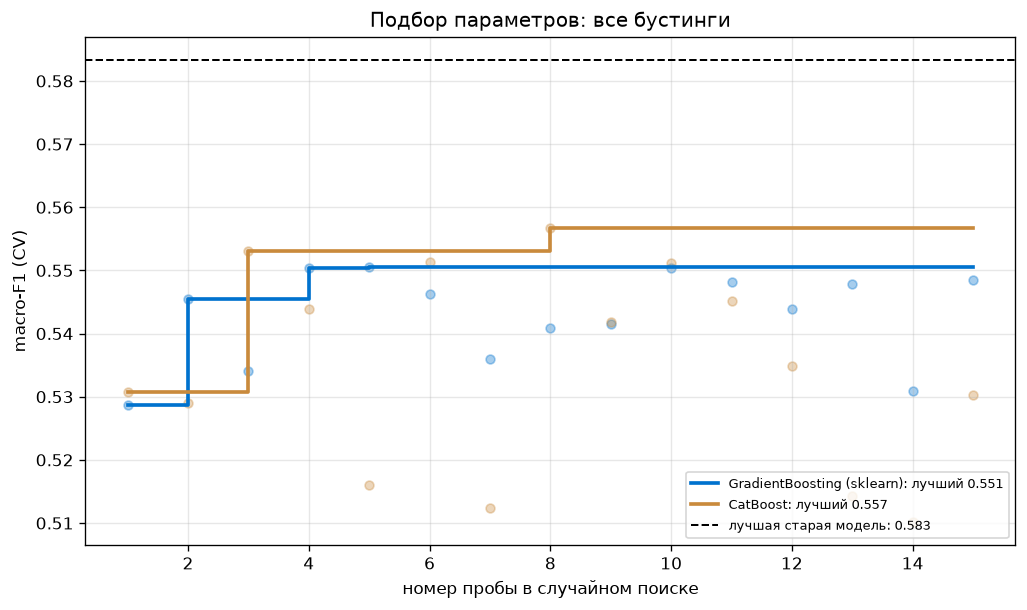

In [28]:
display(Image(filename=str(RES / "gb_search.png")))


## 3. Сколько деревьев и какой темп обучения

Для леса число деревьев выходило на плато. У бустинга качество сначала растёт, потом **падает**: лишние деревья подгоняют
модель под шум. Чем меньше темп обучения, тем позже достигается максимум. Берём параметры, найденные в шаге 2, и для каждой
модели строим качество на CV в зависимости от числа деревьев. Модель обучается один раз до максимума, а оценки на
меньшем числе деревьев берутся из «этапов» (`staged_predict`, у CatBoost — `ntree_end`). Берём **наименьшее** число деревьев
в пределах 0.002 от лучшего.

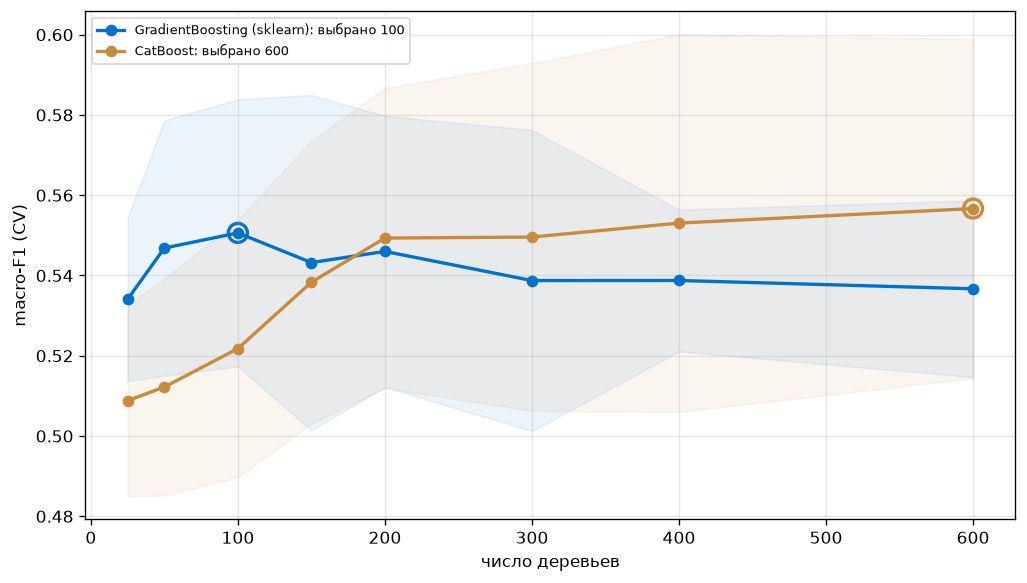

In [29]:
display(Image(filename=str(RES / "gb_n_estimators.png")))


In [30]:
N_BEST = {"GradientBoosting (sklearn)": 100, "CatBoost": 600}       # выбрано по графику выше
print("выбрано деревьев:", N_BEST)


выбрано деревьев: {'GradientBoosting (sklearn)': 100, 'CatBoost': 600}


## 4. Итоговые модели

CV моделей с лучшими параметрами 

In [32]:
cv_saved = pd.read_csv(RES / "cv_table.csv", index_col=0)
show_table(cv_saved.drop(index="hw2_stacking", errors="ignore"))     # общая таблица CV: старые модели, лес и бустинги (стекинг — ниже)


,macro_f1,accuracy,balanced_accuracy,roc_auc_macro,pr_auc_macro,precision_negative,recall_negative,precision_neutral,recall_neutral,precision_positive,recall_positive
hw2_random_forest,0.618,0.684,0.609,0.781,0.640,0.597,0.573,0.747,0.776,0.539,0.478
hw1_tfidf_logreg,0.583,0.704,0.560,0.783,0.621,0.637,0.607,0.740,0.830,0.596,0.243
hw1_kirp_model,0.564,0.701,0.542,0.777,0.609,0.637,0.588,0.731,0.843,0.616,0.196
hw2_gb_catboost,0.556,0.653,0.549,0.754,0.590,0.560,0.559,0.734,0.754,0.401,0.335
hw2_gb_sklearn,0.551,0.651,0.542,0.748,0.587,0.552,0.562,0.730,0.753,0.411,0.313
hw1_bow_logreg,0.529,0.656,0.516,0.703,0.514,0.585,0.505,0.710,0.803,0.374,0.239
hw1_stratified,0.348,0.467,0.349,0.513,0.339,0.329,0.357,0.607,0.584,0.109,0.104
hw1_most_frequent,0.248,0.593,0.333,0.500,0.333,0.000,0.000,0.593,1.000,0.000,0.000


In [33]:
GB_MODELS = {"GradientBoosting (sklearn)": "hw2_gb_sklearn", "CatBoost": "hw2_gb_catboost"}
best_old = cv_saved[cv_saved.index.str.startswith("hw1_")]["macro_f1"].max()
for title, file in GB_MODELS.items():
    f1 = cv_saved.loc[file, "macro_f1"]
    print(f"{title:36s} {f1:.3f} | лучшая старая: {best_old:.3f} | разница: {f1 - best_old:+.3f}")
best_title = max(GB_MODELS, key=lambda t: cv_saved.loc[GB_MODELS[t], "macro_f1"])
print("лучший бустинг на CV:", best_title)


GradientBoosting (sklearn)           0.551 | лучшая старая: 0.583 | разница: -0.032
CatBoost                             0.556 | лучшая старая: 0.583 | разница: -0.027
лучший бустинг на CV: CatBoost


## 5. Важность признаков

У `GradientBoosting`, как у леса, есть MDI (`feature_importances_`): насколько признак в среднем уменьшал потери
в деревьях. У CatBoost — своя мера (`feature_importances_`: на сколько меняется ответ модели при разных значениях признака).
У `HistGradientBoosting` MDI нет, поэтому для него считаем **перестановочную важность** (на сколько падает macro-F1,
если перемешать признак) на отложенном блоке CV. Все важности нормированы на сумму 1, чтобы столбцы можно было сравнивать
(значения разных мер всё равно не идентичны; смотрите на порядок признаков).
Признаки SVD — это «темы», а не слова; их важность лучше смотреть суммой по группе (вторая таблица).

In [34]:
importance_table = pd.read_csv(RES / "gb_importance.csv", index_col=0)
show_table(importance_table.sort_values(best_title, ascending=False).head(15))


,GradientBoosting (sklearn),CatBoost
all_tfidf__truncatedsvd6,0.029,0.030
all_tfidf__truncatedsvd1,0.029,0.030
all_tfidf__truncatedsvd94,0.015,0.026
last_tfidf__truncatedsvd1,0.017,0.023
last_tfidf__truncatedsvd19,0.024,0.022
last_tfidf__truncatedsvd4,0.017,0.021
last_tfidf__truncatedsvd13,0.021,0.020
numeric__has_assistant_code,0.014,0.018
all_tfidf__truncatedsvd13,0.016,0.018
all_tfidf__truncatedsvd3,0.024,0.018


In [35]:
group_names = {"all_tfidf": "текст всех реплик (SVD)", "last_tfidf": "последняя реплика (SVD)", "numeric": "числовые признаки"}
groups = importance_table.groupby(importance_table.index.str.split("__").str[0]).sum().rename(index=group_names)
show_table(groups)

,GradientBoosting (sklearn),CatBoost
текст всех реплик (SVD),0.730,0.727
последняя реплика (SVD),0.211,0.204
числовые признаки,0.059,0.068


## Шаг 6. Test


In [36]:
test_saved = pd.read_csv(RES / "test_table.csv", index_col=0)
display(show_table(test_saved.drop(index="hw2_stacking", errors="ignore")))      # test: старые модели, лес и бустинги


,macro_f1,accuracy,balanced_accuracy,roc_auc_macro,pr_auc_macro,precision_negative,recall_negative,precision_neutral,recall_neutral,precision_positive,recall_positive
hw2_random_forest,0.637,0.712,0.622,0.795,0.640,0.635,0.564,0.758,0.820,0.581,0.481
hw1_tfidf_logreg,0.593,0.727,0.559,0.776,0.642,0.692,0.564,0.738,0.882,0.750,0.231
hw2_gb_sklearn,0.591,0.664,0.593,0.733,0.594,0.571,0.520,0.736,0.761,0.464,0.500
hw2_gb_catboost,0.589,0.662,0.596,0.746,0.604,0.564,0.542,0.746,0.746,0.441,0.500
hw1_kirp_model,0.581,0.724,0.547,0.781,0.639,0.685,0.570,0.731,0.879,1.000,0.192
hw1_bow_logreg,0.494,0.654,0.484,0.676,0.493,0.608,0.486,0.702,0.811,0.242,0.154
hw1_stratified,0.324,0.452,0.324,0.493,0.331,0.277,0.291,0.606,0.586,0.091,0.096
hw1_most_frequent,0.252,0.606,0.333,0.500,0.333,0.000,0.000,0.606,1.000,0.000,0.000


In [50]:
print("матрица ошибок лучшего по CV бустинга:", best_title)
show_table(pd.read_csv(RES / "gb_confusion_matrix.csv", index_col=0), axis=None)


матрица ошибок лучшего по CV бустинга: CatBoost


,предсказано negative,предсказано neutral,предсказано positive
факт negative,97,73,9
факт neutral,66,265,24
факт positive,9,17,26


# Стекинг

Ниже собраны результаты, которые уже были посчитаны в `hw2_stacking.ipynb`.

## 1. Базовые модели

Все базовые модели принимают **таблицу** `make_frame`.

Старые модели HW1 оборачиваются в пайплайн, чтобы обучаться на `dialog_text` (`itemgetter`, а не лямбда, т.к. лямбду нельзя сохранить в `joblib`);

`DummyClassifier`-ы из HW1 (`most_frequent`, `stratified`) базовыми не берём, так как они совсем глупые

`Pavel_Dimon_ARTIFACTS` (имена файлов из `artifacts/` без `.joblib`).
Модель клонируется с её гиперпараметрами и переобучается внутри стекинга; на вход ей должна идти таблица `make_frame`.

In [38]:
BASES = ["hw1_bow_logreg", "hw1_tfidf_logreg", "hw1_kirp_model", "hw2_random_forest", "hw2_gb_sklearn"]      # базовые модели стекинга
BASES


['hw1_bow_logreg',
 'hw1_tfidf_logreg',
 'hw1_kirp_model',
 'hw2_random_forest',
 'hw2_gb_sklearn']

## 2. Предсказания вне блоков и вложенная схема без утечки

Блоки кросс-валидации: $B_0,\dots,B_4$. Для каждой базовой модели считаем:

- `oof[name]` — вероятности для блока $B_k$ от модели, обученной на остальных четырёх блоках («внешние» предсказания);
- `inner[(name, k, j)]` — вероятности для блока $B_j$ от модели, обученной на блоках **без $B_k$ и без $B_j$**.

Тогда оценка стекинга для внешнего блока $B_k$ устроена так: метамодель учится на `inner[(·, k, j)]`, $j\ne k$, — там базовые модели не видели ни метки блока $j$, ни метки блока $k$ — и применяется к `oof[·][B_k]`.

Метки блока $B_k$ нигде не участвуют в обучении ни базовых моделей, ни метамодели.

Если же учить метамодель просто на `oof` оставшихся блоков, то эти предсказания получены моделями, **видевшими** $B_k$: это мягкая утечка, и оценка стекинга получается завышенной. Дальше в разделе 5 сравним оба варианта.

Всё это — 5 + 20 обучений каждой модели.

In [40]:
cv_saved = pd.read_csv(RES / "cv_table.csv", index_col=0)
old_rows = cv_saved[cv_saved.index.str.startswith("hw1_")]
best_old_name, best_old_f1 = old_rows["macro_f1"].idxmax(), old_rows["macro_f1"].max()

pd.read_csv(RES / "stacking_base_table.csv", index_col=0)      # качество базовых моделей на внешних предсказаниях (oof)


,macro_f1,accuracy,balanced_accuracy,roc_auc_macro
hw2_random_forest,0.613,0.679,0.603,0.783
hw1_tfidf_logreg,0.583,0.704,0.560,0.783
hw1_kirp_model,0.564,0.701,0.542,0.777
hw2_gb_sklearn,0.554,0.657,0.545,0.750
hw1_bow_logreg,0.526,0.657,0.513,0.703


In [41]:
print(f"лучшая старая модель на CV: {best_old_name}, macro-F1 = {best_old_f1:.3f}")


лучшая старая модель на CV: hw1_tfidf_logreg, macro-F1 = 0.583


## 5. Подбор: блендинг и стекинг

Перебрал все возможные сочетания базовых моделей. В качестве объединения использовал среднее вероятностей, т.е. блэндинг, а также три метамодели: логистическая регрессия с разной силой регуляризации `C` и с весами классов / без них, и (для контраста) маленький бустинг


In [42]:
experiments = pd.read_csv(RES / "stacking_experiments.csv")      # путь подбора: все составы и метамодели
experiments[["kind", "subset", "meta", "macro_f1", "accuracy", "balanced_accuracy"]].round(3)


,kind,subset,meta,macro_f1,accuracy,balanced_accuracy
0,stacking,old+forest+boosting,hgb_depth2,0.643,0.729,0.610
1,stacking,old+forest,hgb_depth2,0.639,0.726,0.604
2,stacking,old+forest+boosting,lr_C3.0_plain,0.628,0.716,0.601
3,stacking,old+forest,lr_C3.0_plain,0.626,0.717,0.597
4,stacking,old+forest,lr_C0.3_plain,0.619,0.718,0.587
5,stacking,old+forest+boosting,lr_C0.3_plain,0.618,0.718,0.586
6,blend_mean,forest,-,0.613,0.679,0.603
7,stacking,old+forest,lr_C0.03_balanced,0.608,0.676,0.637
8,stacking,forest+boosting,hgb_depth2,0.608,0.706,0.576
9,stacking,forest+boosting,lr_C3.0_plain,0.606,0.696,0.576


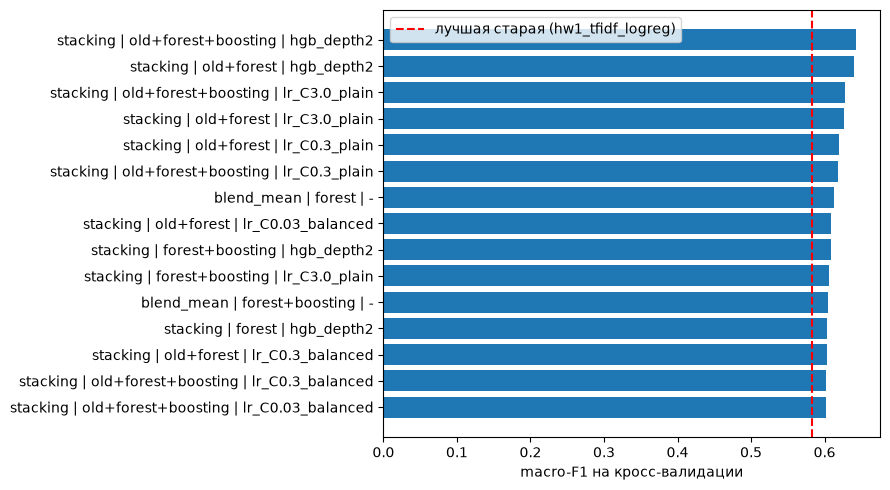

In [43]:
top = experiments.head(15).iloc[::-1]
plt.figure(figsize=(9, 5))
plt.barh(top["kind"] + " | " + top["subset"] + " | " + top["meta"], top["macro_f1"])
plt.axvline(best_old_f1, color="red", ls="--", label=f"лучшая старая ({best_old_name})")
plt.xlabel("macro-F1 на кросс-валидации"); plt.legend(); plt.tight_layout(); plt.show()

### Выбор конфигурации и проверка утечки

Лучшая конфигурация среди допустимых. Для неё же считаем «наивную» оценку (метамодель учится на `oof` оставшихся блоков, которые получены моделями, видевшими проверочный блок) и сравниваем с честной вложенной.

In [45]:
cfg = json.loads((RES / "stacking_config.json").read_text(encoding="utf-8"))
print(f"выбрано: базовые = {cfg['base_models']}, метамодель = {cfg['meta_model']}")
print(f"лучшая старая: {cfg['best_old']['name']}, macro-F1 = {cfg['best_old']['cv_macro_f1']:.3f} | "
      f"стекинг: {cfg['cv_macro_f1_nested']:.3f} | выигрыш {cfg['cv_macro_f1_nested'] - cfg['best_old']['cv_macro_f1']:+.3f}")

pd.read_csv(RES / "stacking_leak.csv", index_col=0)      # вложенная оценка vs наивная (с утечкой)


выбрано: базовые = ['hw1_bow_logreg', 'hw1_tfidf_logreg', 'hw1_kirp_model', 'hw2_random_forest', 'hw2_gb_sklearn'], метамодель = hgb_depth2
лучшая старая: hw1_tfidf_logreg, macro-F1 = 0.583 | стекинг: 0.643 | выигрыш +0.060


,вложенно (без утечки),наивно (с утечкой),разница
macro_f1,0.6432,0.6180,-0.0252
accuracy,0.7287,0.7154,-0.0132
balanced_accuracy,0.6097,0.5851,-0.0246
roc_auc_macro,0.8075,0.8073,-0.0002


## 6. Финальная модель

Финальный стекинг — один sklearn-пайплайн, который целиком принимает таблицу `make_frame`:

- первый шаг называется **`features`** — по нему `su.uses_frame` понимает, что модели нужна таблица, а не список строк (шаг пропускает таблицу как есть);
- `StackingClassifier(cv=folds)` строит метапризнаки на **тех же блоках**, что и вся кросс-валидация, и затем переобучает базовые модели на всём train.

Никаких лямбд и классов из ноутбука: всё, что нужно для загрузки, есть в `sklearn` и `solution_utils` (токенайзер `smart_tokenizer`).

### Веса метамодели: какие базовые модели и для каких классов она считает важными

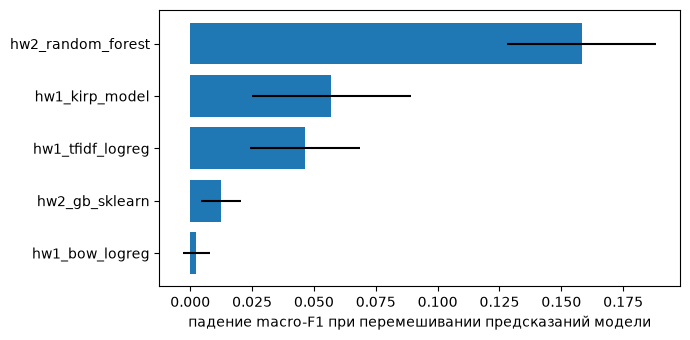

,падение macro-F1 (среднее),std
hw2_random_forest,0.1582,0.0302
hw1_kirp_model,0.0570,0.0322
hw1_tfidf_logreg,0.0465,0.0222
hw2_gb_sklearn,0.0123,0.0081
hw1_bow_logreg,0.0025,0.0054


In [47]:
meta_importance = pd.read_csv(RES / "stacking_meta_importance.csv", index_col=0)

plt.figure(figsize=(7, 3.5))
plt.barh(meta_importance.index[::-1], meta_importance["падение macro-F1 (среднее)"][::-1],
         xerr=meta_importance["std"][::-1])
plt.xlabel("падение macro-F1 при перемешивании предсказаний модели")
plt.tight_layout(); plt.show()

meta_importance


## 7. Тест

Сохраняем модель, строку кросс-валидации (вложенная оценка выбранной конфигурации) и **единственный раз** считаем метрики на тесте.

In [48]:
cv_table = pd.read_csv(RES / "cv_table.csv", index_col=0)
test_table = pd.read_csv(RES / "test_table.csv", index_col=0)
cols = ["macro_f1", "accuracy", "balanced_accuracy"]
pd.concat({"cv": cv_table[cols], "test": test_table[cols]}, axis=1).round(3)      # итоговая таблица: CV и test


cv                                test           \
                  macro_f1 accuracy balanced_accuracy macro_f1 accuracy   
hw2_stacking         0.643    0.729             0.610    0.656    0.746   
hw2_random_forest    0.618    0.684             0.609    0.637    0.712   
hw1_tfidf_logreg     0.583    0.704             0.560    0.593    0.727   
hw1_kirp_model       0.564    0.701             0.542    0.581    0.724   
hw2_gb_catboost      0.556    0.653             0.549    0.589    0.662   
hw2_gb_sklearn       0.551    0.651             0.542    0.591    0.664   
hw1_bow_logreg       0.529    0.656             0.516    0.494    0.654   
hw1_stratified       0.348    0.467             0.349    0.324    0.452   
hw1_most_frequent    0.248    0.593             0.333    0.252    0.606   

                                     
                  balanced_accuracy  
hw2_stacking                  0.617  
hw2_random_forest             0.622  
hw1_tfidf_logreg              0.559  
hw1_kirp_model                0.547  
hw2_gb_catboost               0.596  
hw2_gb_sklearn                0.593  
hw1_bow_logreg                0.484  
hw1_stratified                0.324  
hw1_most_frequent             0.333

# Сравнение ошибок

## Матрицы ошибок

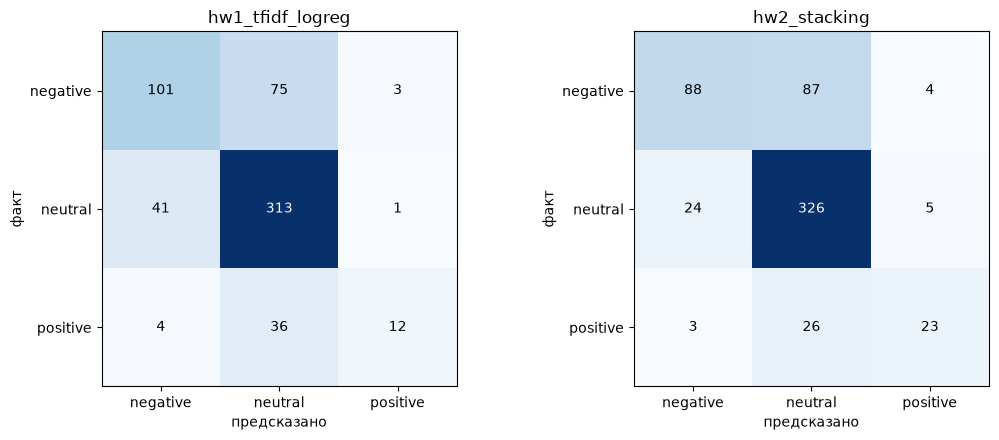

In [55]:
cv_all = pd.read_csv(RES / "cv_table.csv", index_col=0)
best_hw1 = cv_all[cv_all.index.str.startswith("hw1_")]["macro_f1"].idxmax()     # лучшая из HW1 по CV
best_hw2 = cv_all[cv_all.index.str.startswith("hw2_")]["macro_f1"].idxmax()     # лучшая из HW2 по CV

X_test_old = [su.old_dialog_text(d) for d in test_dialogs]                      # вход моделей HW1: текст диалога
X_test_frame = su.make_frame(test_dialogs, su.load_flags())                     # вход моделей HW2: таблица make_frame

pred_hw1 = su.load_models("hw1_")[best_hw1].predict(X_test_old)
pred_hw2 = su.load_models("hw2_")[best_hw2].predict(X_test_frame)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, name, pred in zip(axes, [best_hw1, best_hw2], [pred_hw1, pred_hw2]):
    cm = confusion_matrix(y_test, pred, labels=CLASSES)
    ax.imshow(cm, cmap="Blues")
    ax.set_xticks(range(len(CLASSES)), CLASSES); ax.set_yticks(range(len(CLASSES)), CLASSES)
    ax.set_xlabel("предсказано"); ax.set_ylabel("факт")
    ax.set_title(f"{name}\nmacro-F1 (test) = {su.all_metrics(y_test, pred_proba)['macro_f1']:.3f}" if False else name)
    for i in range(len(CLASSES)):
        for j in range(len(CLASSES)):
            ax.text(j, i, cm[i, j], ha="center", va="center",
                    color="white" if cm[i, j] > cm.max() / 2 else "black")
plt.tight_layout(); plt.show()

# Где новая модель исправила ошибку старой, а где ошиблась сама

Сравниваем на **test** лучшую старую модель по CV (`hw1_tidf_logreg*`) и итоговый стекинг (`hw2_stacking`). Для каждого диалога смотрим, угадала ли каждая из моделей реакцию:

- **исправила** — старая ошиблась, новая угадала;
- **испортила** — старая угадывала, новая ошиблась.

Диалоги, где обе угадали или обе ошиблись, в таблицу не попадают. 

In [ ]:
OLD_NAME = cv_saved.loc[cv_saved.index.str.startswith("hw1_"), "macro_f1"].idxmax()      # лучшая старая модель по CV
NEW_NAME = "hw2_stacking"                                                                   # новая модель

old_model = su.load_models("hw1_")[OLD_NAME]
new_model = su.load_models("hw2_")[NEW_NAME]

X_test_frame = su.make_frame(test_dialogs, su.load_flags())            # вход новых моделей: таблица make_frame
X_test_old = [su.old_dialog_text(d) for d in test_dialogs]             # вход старых моделей: текст диалога

old_pred = np.asarray(old_model.predict(X_test_old))
new_pred = np.asarray(new_model.predict(X_test_frame))
old_ok, new_ok = old_pred == y_test, new_pred == y_test

cmp = pd.DataFrame({
    "dialog_id": X_test_frame["dialog_id"].to_numpy(),
    "факт": y_test,
    f"старая ({OLD_NAME})": old_pred,
    f"новая ({NEW_NAME})": new_pred,
    "результат": np.select([~old_ok & new_ok, old_ok & ~new_ok], ["исправила", "испортила"], default=""),
    "последняя реплика пользователя": X_test_frame["last_user"].to_numpy(),
    "диалог": X_test_frame["dialog_text"].to_numpy(),
})

summary = pd.Series({
    "обе угадали": int((old_ok & new_ok).sum()),
    "новая исправила старую": int((~old_ok & new_ok).sum()),
    "новая испортила (старая была права)": int((old_ok & ~new_ok).sum()),
    "обе ошиблись": int((~old_ok & ~new_ok).sum()),
}, name="диалогов на test")
display(summary.to_frame())

diff_table = cmp[cmp["результат"] != ""].sort_values(["результат", "факт"]).reset_index(drop=True)
diff_table.to_csv("artifacts/results/new_vs_old_errors.csv", index=False, encoding="utf-8")      # полные тексты — в csv

show = diff_table.copy()
show["последняя реплика пользователя"] = show["последняя реплика пользователя"].str.slice(0, 200)
show["диалог"] = show["диалог"].str.slice(0, 400)
with pd.option_context("display.max_colwidth", 400, "display.max_rows", 500):
    display(show)


,диалогов на test
обе угадали,404
новая исправила старую,33
новая испортила (старая была права),22
обе ошиблись,127


,dialog_id,факт,старая (hw1_tfidf_logreg),новая (hw2_stacking),результат,последняя реплика пользователя,диалог
0,db3a30e7e53,negative,negative,neutral,испортила,provide the requirement.. rephrase,"hey as a Product owner.. I need to communicate my requirements as a feature for the thirty day calendar to be displayed in the ecommerce website to my back end developers so that they work on changes to the API. ""Need - As the availability of the redemption seats are comparatively low than the revenue tickets. Introduce a thirty day calendar to view the lowest fare information for each day ov..."
1,d5f0720ea1e,negative,negative,neutral,испортила,savefileasynch vs copytoasnch,"can i create controller in aspnet core automatically from models? Yes, you can generate controllers automatically from models in ASP.NET Core using scaffolding. Scaffolding is a code generation framework that allows you to quickly create the controller class and associated views based on your models.\n\nTo scaffold a controller, you can use the built-in command-line tool called ""dotnet-aspnet-..."
2,dd2cf91780d,negative,negative,neutral,испортила,summarise the information from here in a table: https://www.igem.org.uk/events-and-training/event-and-training-calendar.html,"how can i use powerautomate to add every email flagged with the blue category to a planner list To achieve this, you can follow the steps below:\n\n1. Create a new flow in your Power Automate account.\n\n2. Select ""When a new email arrives (V3)"" as the trigger for your flow.\n\n3. Connect your email account and select the folder where the flagged emails reside.\n\n4. Add a condition action to ..."
3,d0add1f73cf,negative,negative,neutral,испортила,But the de facto borders weren't changed. I'm referring to de facto border changes.,"What is one country, that, without changing its borders, lost all their neighbors? Lesotho is a country that is completely surrounded by South Africa and has no other neighboring countries. Poland. I apologize for my mistake. You are correct, Poland lost all of its neighbors without changing its borders after World War II when the Soviet Union annexed Lithuania, Belarus, and Ukraine to the eas..."
4,db199ce1b85,negative,negative,neutral,испортила,same requirement for following question:\nCalculate all the drivers who departed or reached the airport as the destination?,"Based on ride share company star schema, please use SQL query to solve following question:\n calculate all customers who have only departed from or arrived at the airport as their destination, and excluding those who have been to other destinations. To effectively provide an SQL solution, I'll give you an example schema and solution based on a typical ride-share company star schema layout. Let..."
5,d305f4f188a,negative,negative,neutral,испортила,"pragma solidity ^ 0.8.7;\n\ncontract Owner {\n address blic owner;\n uint private code;\n\n constructor (address _owner, uint _code) {\n owner = _owner;\n code = _code;\n }\n functi","conrtract A {\n function test() virtual public pure returns (uint) {\n return 123;\n }\n}\n\nconrtract B {\n function test() virtual public pure returns (uint) {\n return 456;\n }\n}\n\nconrtract C is A, B {\n function test() override (A, B) public pure returns (uint) {\n return super.test();\n }\n}\nWhat does C.test() return? C.test() will return a compi..."
6,d89835bb6b0,negative,negative,neutral,испортила,Given this data set how would i got about using feature selection techniques and data visualization using pandas on python to eventually determine the predicted rate of bee colony loss after 2021 as w,"In Tidy Tuesday there is a data set about the loss of bee colonies, this incudes a few different graphs including the percent of lost colonies dependent on different factors like diseases, weather, starvation etc. It also has data on maximum colonies, renovated colonies, loss percent etc. per state and added up in the entire US in timeline of a 3 month period from 2015-2020. H